In [ ]:
import pandas as pd
import numpy as np
ruta = "../data/processed/default of credit card clients.xls"
df= pd.read_excel(ruta, header=1)  #Header=1 indica que los encabezados estan en la segunda columna
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## EDA

#### Limpieza y validacion de datos

In [5]:
#Validar dimensiones de la base de datos.
df.shape

(30000, 25)

In [6]:
#Revisar tipos de datos: Las 25 columnas estan siendo interpretadas como texto.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

- En este conjunto de datos en particular, las 25 columnas representan valores numericos.

In [7]:
#Convertir columnas a sus tipos correctos.
df = df.apply(pd.to_numeric, errors="coerce")  #coerce pone los valores en Nan de los datos que no puede convertir
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [ ]:
#Revisar si existen valores faltantes: No hay valores faltantes.
print("Valores faltantes por columna:")
print(df.isnull().sum())

print("\nTotal de valores faltantes:", df.isnull().sum().sum())


Valores faltantes por columna:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

Total de valores faltantes: 0


In [11]:
# Identificar si hay registros duplicados:

print("Cantidad de ID duplicados:", df["ID"].duplicated().sum())

print(
    "Cantidad de filas completamente duplicadas:",
    df.duplicated().sum()
)

print(
    "Cantidad de filas duplicadas sin considerar ID:",
    df.drop(columns=["ID"]).duplicated().sum()
)


Cantidad de ID duplicados: 0
Cantidad de filas completamente duplicadas: 0
Cantidad de filas duplicadas sin considerar ID: 35


- Tenemos clientes con identificadores diferentes, pero tienen exactamente los mismos valores en las demás variables.

In [12]:
#Detallar los registros duplicados
duplicados = df[df.drop(columns=["ID"]).duplicated(keep=False)]
duplicados.sort_values(by=df.columns[1:].tolist())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
12430,12431,20000,1,2,2,24,2,2,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
14294,14295,20000,1,2,2,24,2,2,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
1759,1760,50000,1,2,2,26,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
10250,10251,50000,1,2,2,26,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
7170,7171,50000,2,1,2,23,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27966,27967,360000,2,1,2,27,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
18325,18326,360000,2,1,2,29,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
22162,22163,360000,2,1,2,29,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
839,840,500000,1,1,1,43,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1


In [13]:
#Medir cuantos clientes representan los duplicados:
# Contar los grupos de registros duplicados sin considerar ID
grupos_duplicados = (
    df.drop(columns=["ID"])
    .value_counts()
)

grupos_duplicados = grupos_duplicados[grupos_duplicados > 1]

print("Cantidad de grupos duplicados:", len(grupos_duplicados))
print("Cantidad total de filas en esos grupos:", grupos_duplicados.sum())

Cantidad de grupos duplicados: 35
Cantidad total de filas en esos grupos: 70


- Encontramos 35 pares de clientes con información identica en las 24 variables distintas a ID, sin embargo no tenemos evidencia suficiente para decir que son errores.

In [14]:
#Validar valores unicos de la base: 
df.nunique().sort_values()

SEX                               2
default payment next month        2
MARRIAGE                          4
EDUCATION                         7
PAY_5                            10
PAY_6                            10
PAY_2                            11
PAY_4                            11
PAY_3                            11
PAY_0                            11
AGE                              56
LIMIT_BAL                        81
PAY_AMT5                       6897
PAY_AMT4                       6937
PAY_AMT6                       6939
PAY_AMT3                       7518
PAY_AMT2                       7899
PAY_AMT1                       7943
BILL_AMT6                     20604
BILL_AMT5                     21010
BILL_AMT4                     21548
BILL_AMT3                     22026
BILL_AMT2                     22346
BILL_AMT1                     22723
ID                            30000
dtype: int64

- Education: Hay códigos adicionales a los documentados en el portal: 1 = posgrado; 2 = universidad; 3 = educación secundaria;  4 = otros. En la base tenemos mas codigos.

Marriage: Debe tener 1 = casado/a; 2 = soltero/a; 3 = otros y tenemos 4 en la base.

In [15]:
#Validando cantidad de datos en estados no identificados para EDUCATION.
df["EDUCATION"].value_counts().sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [16]:
#Total de estados desconocidos en educación
(~df["EDUCATION"].isin([1, 2, 3, 4])).sum()

np.int64(345)

- 0 código no especificado
- 5 código no especificado
- 6 código no especificado

Los codigos 0, 5 y 6 suman 345 registros. Se agruparan estos códigos en la catergoría 4 "otros"

In [ ]:
#Agrupando los codigos: 0, 5 y 6 en la categoria 4
df["EDUCATION"] = df["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4
})

In [ ]:
#Validando que en Education solo queden 4 categorías: ok EDUCATION quedó con las categorías correctas.
df["EDUCATION"].value_counts().sort_index()

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

In [ ]:
#Validando categoría Marriage: El codigo 0 no esta especificado
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

- 0 código no especificado: Se agruoa en la categoría "otros"

In [22]:
#Reemplazar los valores de 0 a 3
df["MARRIAGE"] = df["MARRIAGE"].replace({
    0: 3,
})

In [23]:
#validando que es Marriage solo queden las 3 categorías definidas.
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64

In [32]:
#Analizando la variable PAY_0: Esta variable representa el pago de la tarjeta en sep 2025.
#Es importante para entender el comportamiento de pago de los clientes.
interpretacion_pay0 = {
    -2: "Sin consumo",
    -1: "Pago realizado a tiempo",
     0: "Pago mínimo (según la documentación)",
     1: "Retraso de un mes",
     2: "Retraso de dos meses",
     3: "Retraso de tres meses",
     4: "Retraso de cuatro meses",
     5: "Retraso de cinco meses",
     6: "Retraso de seis meses",
     7: "Retraso de siete meses",
     8: "Retraso de ocho meses"
}

# Calcular la cantidad de registros por código
resultado_pay0 = df["PAY_0"].value_counts().sort_index().reset_index()

# Agregar la interpretación de cada código
resultado_pay0.columns = ["Código", "Cantidad"]
resultado_pay0["Interpretación"] = resultado_pay0["Código"].map(interpretacion_pay0)

# Mostrar el resultado como tabla
display(resultado_pay0[["Código", "Interpretación", "Cantidad"]])

,Código,Interpretación,Cantidad
0,-2,Sin consumo,2759
1,-1,Pago realizado a tiempo,5686
2,0,Pago mínimo (según la documentación),14737
3,1,Retraso de un mes,3688
4,2,Retraso de dos meses,2667
5,3,Retraso de tres meses,322
6,4,Retraso de cuatro meses,76
7,5,Retraso de cinco meses,26
8,6,Retraso de seis meses,11
9,7,Retraso de siete meses,9


In [ ]:
#Revisando los codigos de tienen registrados las variables Pay: ok concuerdan con documentacion.
variables_pay = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

codigos_por_pay = pd.DataFrame([
    {
        "Variable": variable,
        "Códigos encontrados": sorted(df[variable].dropna().unique().tolist())
    }
    for variable in variables_pay
])

display(codigos_por_pay)


,Variable,Códigos encontrados
0,PAY_0,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
1,PAY_2,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
2,PAY_3,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
3,PAY_4,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
4,PAY_5,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]"
5,PAY_6,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]"


In [ ]:
#Revisar las categorías de sex: ok 1 y 2 son los codigos que estan en la documentacion.
df["SEX"].value_counts().sort_index()

SEX
1    11888
2    18112
Name: count, dtype: int64

In [ ]:
#Validando variable facturación: ok los valores negativos se conservan, podrian representar ajustes o saldos a favor.
variables_bill = [f"BILL_AMT{i}" for i in range(1, 7)]

resumen_bill = pd.DataFrame({
    "Valores negativos": (df[variables_bill] < 0).sum(),
    "Valores iguales a cero": (df[variables_bill] == 0).sum(),
    "Valores positivos": (df[variables_bill] > 0).sum(),
    "Valores faltantes": df[variables_bill].isnull().sum()
})

display(resumen_bill)


,Valores negativos,Valores iguales a cero,Valores positivos,Valores faltantes
BILL_AMT1,590,2008,27402,0
BILL_AMT2,669,2506,26825,0
BILL_AMT3,655,2870,26475,0
BILL_AMT4,675,3195,26130,0
BILL_AMT5,655,3506,25839,0
BILL_AMT6,688,4020,25292,0


In [ ]:
#Vaidando variable pay: ok no se encontraron valores negativos ni datos faltantes.
variables_pay_amt = [f"PAY_AMT{i}" for i in range(1, 7)]

resumen_pay_amt = pd.DataFrame({
    "Valores negativos": (df[variables_pay_amt] < 0).sum(),
    "Valores iguales a cero": (df[variables_pay_amt] == 0).sum(),
    "Valores positivos": (df[variables_pay_amt] > 0).sum(),
    "Valores faltantes": df[variables_pay_amt].isnull().sum()
})

display(resumen_pay_amt)

,Valores negativos,Valores iguales a cero,Valores positivos,Valores faltantes
PAY_AMT1,0,5249,24751,0
PAY_AMT2,0,5396,24604,0
PAY_AMT3,0,5968,24032,0
PAY_AMT4,0,6408,23592,0
PAY_AMT5,0,6703,23297,0
PAY_AMT6,0,7173,22827,0


In [44]:
# Revisando la distribución de la variable objetivo

variable_objetivo = "default payment next month"

conteo_impago = df[variable_objetivo].value_counts().sort_index()

resumen_impago = pd.DataFrame({
    "Cantidad de clientes": conteo_impago,
    "Porcentaje (%)": (
        conteo_impago / len(df) * 100
    ).round(2)
})

resumen_impago.index = resumen_impago.index.map({
    0: "No presentó impago",
    1: "Presentó impago"
})

display(resumen_impago)


,Cantidad de clientes,Porcentaje (%)
default payment next month,,
No presentó impago,23364,77.88
Presentó impago,6636,22.12


Revisión de la variable objetivo

La variable `default payment next month` es una variable binaria que identifica si el cliente presentó impago en el mes siguiente. El valor 0 representa a los clientes que no presentaron impago y el valor 1 a quienes sí lo presentaron.

De los 30.000 registros analizados, 23.364 clientes (77,88 %) no presentaron impago, mientras que 6.636 clientes (22,12 %) sí lo hicieron.

Se observa una mayor proporción de clientes sin impago. Esta diferencia en la distribución de las categorías deberá tenerse en cuenta durante la evaluación de los modelos predictivos.

In [45]:
# Revisar los rangos de las variables principales

variables_revision = [
    "LIMIT_BAL",
    "AGE",
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    "default payment next month"
]

for variable in variables_revision:
    print(f"\n{variable}")
    print("Mínimo:", df[variable].min())
    print("Máximo:", df[variable].max())
    print("Valores faltantes:", df[variable].isnull().sum())


LIMIT_BAL
Mínimo: 10000
Máximo: 1000000
Valores faltantes: 0

AGE
Mínimo: 21
Máximo: 79
Valores faltantes: 0

SEX
Mínimo: 1
Máximo: 2
Valores faltantes: 0

EDUCATION
Mínimo: 1
Máximo: 4
Valores faltantes: 0

MARRIAGE
Mínimo: 1
Máximo: 3
Valores faltantes: 0

PAY_0
Mínimo: -2
Máximo: 8
Valores faltantes: 0

PAY_2
Mínimo: -2
Máximo: 8
Valores faltantes: 0

PAY_3
Mínimo: -2
Máximo: 8
Valores faltantes: 0

PAY_4
Mínimo: -2
Máximo: 8
Valores faltantes: 0

PAY_5
Mínimo: -2
Máximo: 8
Valores faltantes: 0

PAY_6
Mínimo: -2
Máximo: 8
Valores faltantes: 0

default payment next month
Mínimo: 0
Máximo: 1
Valores faltantes: 0


In [ ]:
#Validacion final de limpieza
print("Dimensiones de la base:", df.shape)

print("\nTotal de valores faltantes:", df.isnull().sum().sum())

print("IDs duplicados:", df["ID"].duplicated().sum())

print("Filas completamente duplicadas:", df.duplicated().sum())

Dimensiones de la base: (30000, 25)

Total de valores faltantes: 0
IDs duplicados: 0
Filas completamente duplicadas: 0


Limpieza y validación de los datos

Se realizó un proceso de limpieza y validación del conjunto de datos *Default of Credit Card Clients*, con el objetivo de revisar su estructura, identificar posibles inconsistencias y preparar la información para el análisis exploratorio de datos (EDA).

1. Validación de la estructura

La base de datos final conserva **30.000 registros y 25 columnas**, sin cambios en sus dimensiones durante el proceso de limpieza.

2. Tratamiento de variables categóricas

- **EDUCATION:** se agruparon los códigos 0, 5 y 6 en el código 4, para reunir las categorías correspondientes a otros niveles educativos y valores no especificados.
- **MARRIAGE:** se agrupó el código 0 en el código 3, correspondiente a otros estados civiles o valores no especificados.
- **SEX:** se verificaron los códigos existentes, sin necesidad de modificarlos.
- **Historial de pagos:** se revisaron los códigos de las variables `PAY_0`, `PAY_2`, `PAY_3`, `PAY_4`, `PAY_5` y `PAY_6`. Se conservaron los valores observados, sin realizar modificaciones adicionales.

3. Revisión de valores de facturación y pagos

Se revisaron las variables `BILL_AMT1` a `BILL_AMT6` y `PAY_AMT1` a `PAY_AMT6`. Se identificaron valores negativos en las variables de facturación, los cuales se conservaron debido a que podrían representar créditos o ajustes. En las variables de pagos no se encontraron valores negativos. Los valores iguales a cero y positivos también se conservaron.

4. Revisión de registros repetidos

Se identificaron 35 registros con características idénticas al excluir la variable `ID` de la comparación. Estos registros se conservaron, ya que la coincidencia en sus características no demuestra que sean duplicados erróneos. 

5. Resultados de la validación final

| Criterio | Resultado |
|---|---:|
| Registros finales | 30.000 |
| Columnas finales | 25 |
| Valores faltantes | 0 |
| Identificadores duplicados | 0 |
| Filas completamente duplicadas | 0 |

Conclusión

La limpieza inicial permitió verificar la integridad estructural de la base de datos, tratar determinadas categorías y revisar los valores de las variables financieras y del historial de pagos. La validación final confirmó que se conservaron los 30.000 registros, sin valores faltantes.

Con estos resultados, la base queda preparada para continuar con el análisis exploratorio de datos (EDA). Esto no implica que se hayan descartado todas las posibles anomalías estadísticas, las cuales se estudiarán en las siguientes etapas.


In [48]:
# Guardar la base limpia en data/raw
df.to_csv(
    "../data/raw/base_limpia.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Base limpia guardada correctamente en data/raw.")

Base limpia guardada correctamente en data/raw.


In [49]:
#Conocer estructura de la base limpia
print("Dimensiones de la base:", df.shape)

print("\nInformación general de las variables:")
df.info()

Dimensiones de la base: (30000, 25)

Información general de las variables:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 1

In [ ]:
#recomendación: conservemos los nombres originales y documentemos la correspondencia de cada variable con su mes. 
#El salto de Pay_0 a Pay_2 no afecta el análisis ni la predicción.
print("Variables de la base:")
for columna in df.columns:
    print(columna)

Variables de la base:
ID
LIMIT_BAL
SEX
EDUCATION
MARRIAGE
AGE
PAY_0
PAY_2
PAY_3
PAY_4
PAY_5
PAY_6
BILL_AMT1
BILL_AMT2
BILL_AMT3
BILL_AMT4
BILL_AMT5
BILL_AMT6
PAY_AMT1
PAY_AMT2
PAY_AMT3
PAY_AMT4
PAY_AMT5
PAY_AMT6
default payment next month


#### Análisis de la distribucion de las variables demograficas: AGE, SEX, ADECATION, MARRIAGE.

In [56]:
#Estadísticas descriptivas de las variables demográficas

variables_demograficas = [
    "AGE",
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

display(df[variables_demograficas].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
AGE,30000.0,35.49,9.22,21.0,28.0,34.0,41.0,79.0
SEX,30000.0,1.60,0.49,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.84,0.74,1.0,1.0,2.0,2.0,4.0
MARRIAGE,30000.0,1.56,0.52,1.0,1.0,2.0,2.0,3.0


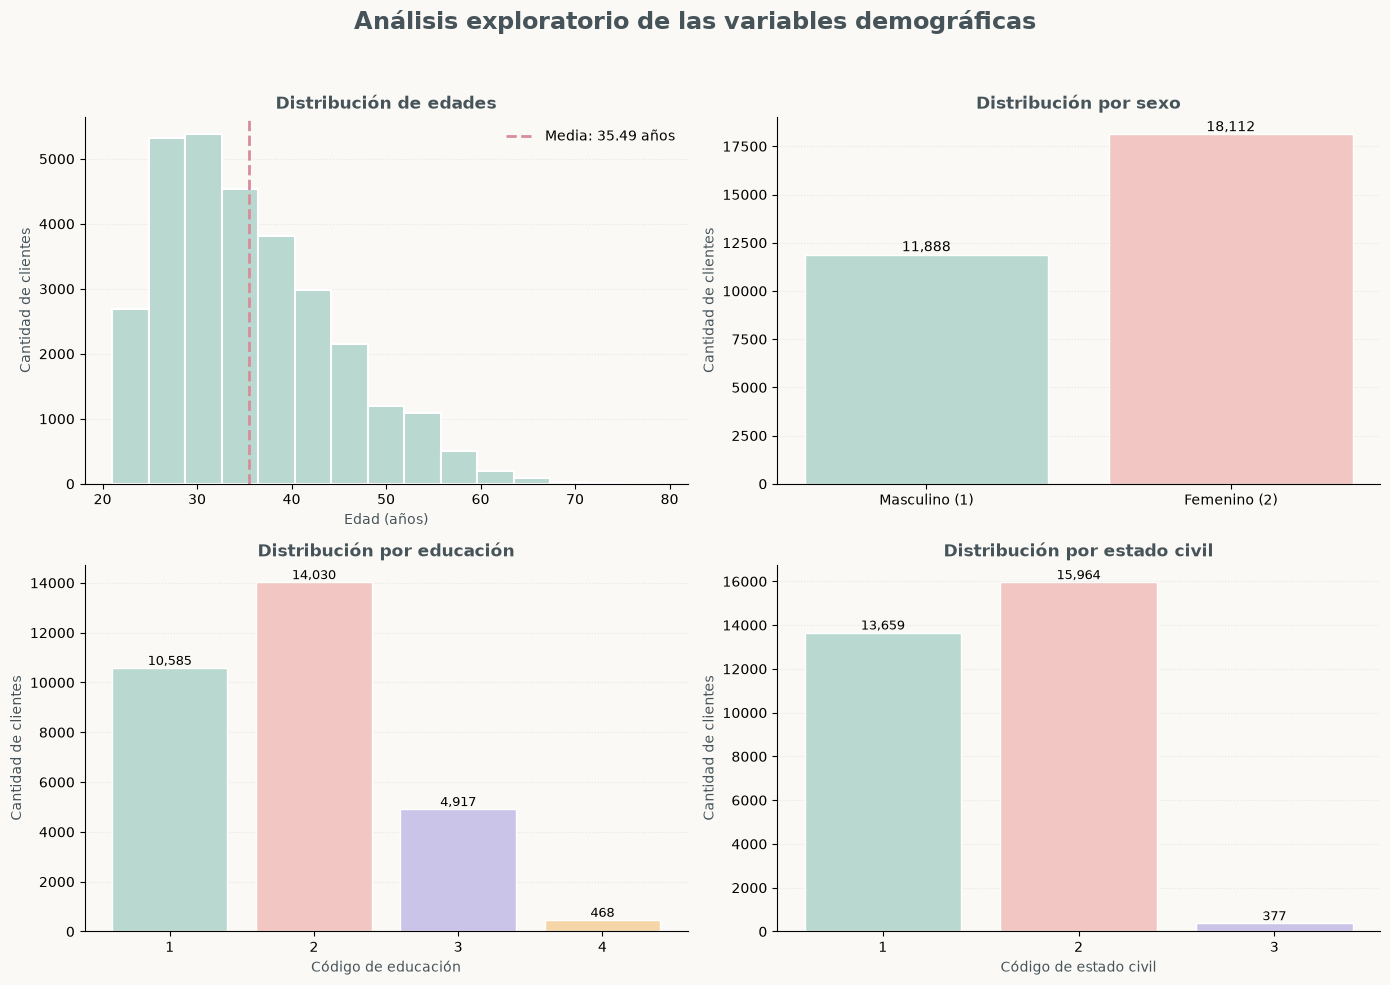

In [55]:
import matplotlib.pyplot as plt

# Paleta de colores pastel
colores = ["#B8D8D0", "#F2C6C2", "#C9C4E8", "#F6D6A8"]
fondo = "#FAF9F6"
texto = "#46545A"

# Crear panel de 4 gráficos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.patch.set_facecolor(fondo)

# 1. Edad
ax = axes[0, 0]
edad_media = df["AGE"].mean()

ax.hist(
    df["AGE"],
    bins=15,
    color=colores[0],
    edgecolor="white",
    linewidth=1.5
)
ax.axvline(
    edad_media,
    color="#D98C9A",
    linestyle="--",
    linewidth=2,
    label=f"Media: {edad_media:.2f} años"
)
ax.set_title("Distribución de edades", fontweight="bold")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Cantidad de clientes")
ax.legend(frameon=False)

# 2. Sexo
ax = axes[0, 1]
sexo = df["SEX"].value_counts().sort_index()
barras = ax.bar(
    ["Masculino (1)", "Femenino (2)"],
    [sexo.get(1, 0), sexo.get(2, 0)],
    color=colores[:2],
    edgecolor="white"
)
ax.set_title("Distribución por sexo", fontweight="bold")
ax.set_ylabel("Cantidad de clientes")

for barra in barras:
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{int(barra.get_height()):,}",
        ha="center",
        va="bottom"
    )

# 3. Educación
ax = axes[1, 0]
educacion = df["EDUCATION"].value_counts().sort_index()
barras = ax.bar(
    educacion.index.astype(str),
    educacion.values,
    color=colores,
    edgecolor="white"
)
ax.set_title("Distribución por educación", fontweight="bold")
ax.set_xlabel("Código de educación")
ax.set_ylabel("Cantidad de clientes")

for barra in barras:
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{int(barra.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# 4. Estado civil
ax = axes[1, 1]
matrimonio = df["MARRIAGE"].value_counts().sort_index()
barras = ax.bar(
    matrimonio.index.astype(str),
    matrimonio.values,
    color=colores,
    edgecolor="white"
)
ax.set_title("Distribución por estado civil", fontweight="bold")
ax.set_xlabel("Código de estado civil")
ax.set_ylabel("Cantidad de clientes")

for barra in barras:
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{int(barra.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Aplicar formato uniforme
for ax in axes.flat:
    ax.set_facecolor(fondo)
    ax.grid(axis="y", linestyle=":", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.title.set_color(texto)
    ax.xaxis.label.set_color(texto)
    ax.yaxis.label.set_color(texto)

fig.suptitle(
    "Análisis exploratorio de las variables demográficas",
    fontsize=17,
    fontweight="bold",
    color=texto
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Se realizó un análisis exploratorio de las variables demográficas `AGE`, `SEX`, `EDUCATION` y `MARRIAGE`, con el propósito de conocer la composición de los clientes de la muestra e identificar patrones en sus características.

1. Distribución de edades (`AGE`)

La base contiene 30.000 registros y 56 edades diferentes, con un rango entre 21 y 79 años. La edad media es de **35,49 años**.

El histograma muestra una mayor concentración de clientes aproximadamente entre los 25 y los 35 años. También se observa una disminución progresiva de las frecuencias en las edades más avanzadas, formando una cola hacia la derecha.

**Interpretación:** la muestra se concentra principalmente en adultos jóvenes y de mediana edad. La presencia de pocos clientes en edades avanzadas no constituye, por sí sola, evidencia de errores en los datos.

La media es mayor (35.49) es mayor que la mediana (34), la distribución presenta una cola hacia las edades mayores, se confirma en el histograma con una cola hacia la derecha.

2. Distribución por sexo (`SEX`)

La distribución de los clientes es la siguiente:

- **Código 1 (masculino):** 11.888 clientes, equivalentes al 39,63 %.
- **Código 2 (femenino):** 18.112 clientes, equivalentes al 60,37 %.

**Interpretación:** existe una mayor representación de mujeres en la muestra, con una diferencia de 6.224 clientes respecto a los hombres. Esta diferencia describe la composición de la base, pero no permite concluir que exista un mayor riesgo de impago en alguna de las dos categorías.

3. Distribución por educación (`EDUCATION`)

Después de la limpieza, la distribución es la siguiente:

| Código | Cantidad de clientes | Porcentaje |
|---|---:|---:|
| 1 | 10.585 | 35,28 % |
| 2 | 14.030 | 46,77 % |
| 3 | 4.917 | 16,39 % |
| 4 | 468 | 1,56 % |
| **Total** | **30.000** | **100 %** |

**Interpretación:** la categoría 2 es la más frecuente, seguida de la categoría 1. En conjunto, ambas representan aproximadamente el 82,05 % de los registros.

Durante la limpieza, los códigos originales 0, 5 y 6 se agruparon en el código 4, junto con los registros que originalmente ya tenían ese código. Por tanto, la categoría 4 reúne distintos valores originales y no representa un único nivel educativo.

4. Distribución por estado civil (`MARRIAGE`)

La distribución después de la limpieza es la siguiente:

| Código | Cantidad de clientes | Porcentaje |
|---|---:|---:|
| 1 | 13.659 | 45,53 % |
| 2 | 15.964 | 53,21 % |
| 3 | 377 | 1,26 % |
| **Total** | **30.000** | **100 %** |

**Interpretación:** las categorías 1 y 2 concentran aproximadamente el 98,74 % de los registros. La categoría 3 tiene una representación reducida.

Durante la limpieza, los registros con el código original 0 se agruparon en el código 3. Por ello, esta última categoría reúne los códigos originales 0 y 3, y no debe interpretarse como una categoría homogénea.

5. Conclusiones del análisis demográfico

El análisis exploratorio permite identificar las siguientes características de la muestra:

- La edad media es de 35,49 años, con una mayor concentración de clientes entre los 25 y los 35 años.
- Las mujeres representan el 60,37 % de los registros, mientras que los hombres representan el 39,63 %.
- Las categorías educativas 1 y 2 reúnen la mayor proporción de clientes.
- Las categorías 1 y 2 del estado civil concentran casi la totalidad de la muestra.
- Las categorías agrupadas durante la limpieza deben interpretarse considerando las transformaciones realizadas.




#### Análisis de la distribucion de las variables financieras: LIMIT_BAL, BILL_AMT, PAY_AMT

In [58]:
#Estadísticas descriptivas de las variables financieras

variables_financieras = [
    "LIMIT_BAL",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

display(df[variables_financieras].describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
BILL_AMT1,30000.0,51223.33,73635.86,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.08,71173.77,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.15,69349.39,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.95,64332.86,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.40,60797.16,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.76,59554.11,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.58,16563.28,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.16,23040.87,0.0,833.00,2009.0,5000.00,1684259.0
PAY_AMT3,30000.0,5225.68,17606.96,0.0,390.00,1800.0,4505.00,896040.0


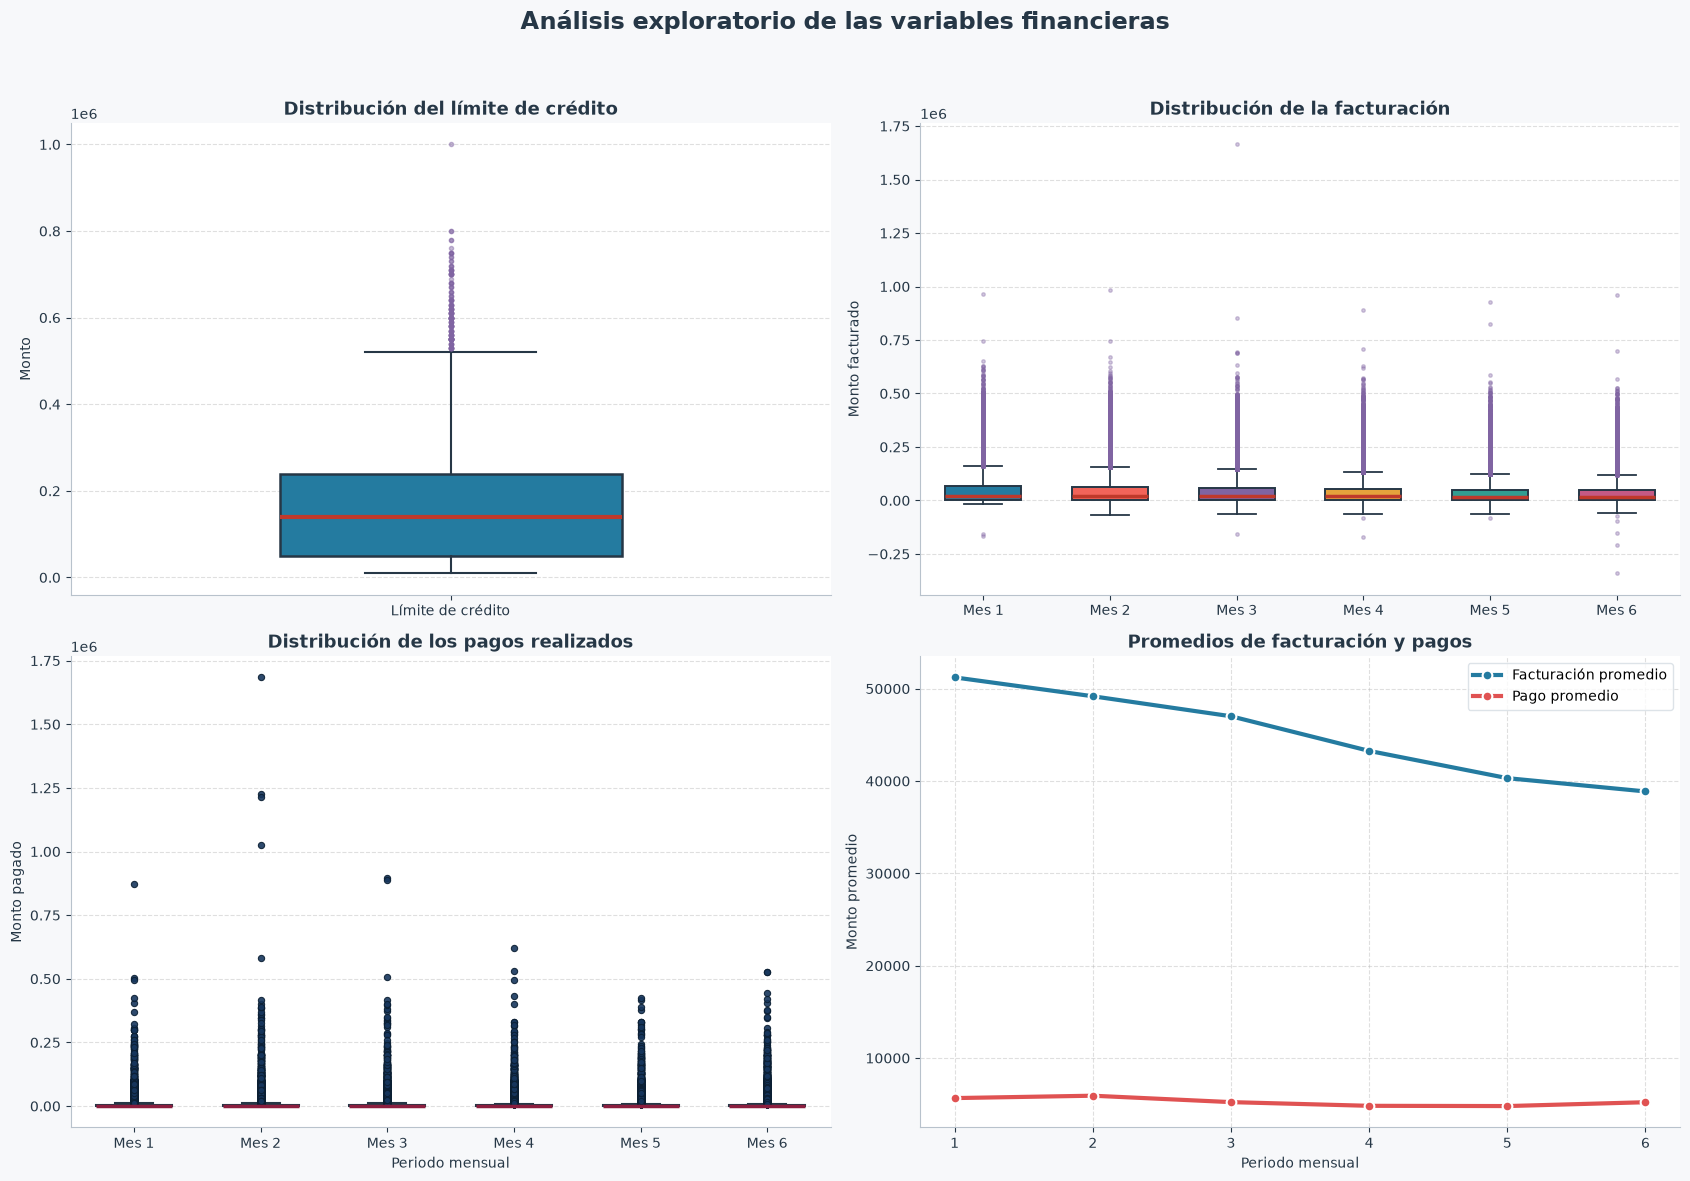

In [61]:
import matplotlib.pyplot as plt

# Paleta profesional con mayor contraste
colores = ["#247BA0", "#F2645A", "#8064A2",
           "#E6A23C", "#329D91", "#C45A85"]
fondo = "#F7F8FA"
texto = "#263746"
color_mediana = "#C0392B"

facturacion = [f"BILL_AMT{i}" for i in range(1, 7)]
pagos = [f"PAY_AMT{i}" for i in range(1, 7)]

fig, axes = plt.subplots(2, 2, figsize=(17, 12))
fig.patch.set_facecolor(fondo)

# 1. Distribución del límite de crédito
ax = axes[0, 0]
ax.boxplot(
    df["LIMIT_BAL"],
    patch_artist=True,
    tick_labels=["Límite de crédito"],
    widths=0.45,
    boxprops=dict(facecolor=colores[0], edgecolor=texto,
                  linewidth=1.8),
    medianprops=dict(color=color_mediana, linewidth=3),
    whiskerprops=dict(color=texto, linewidth=1.5),
    capprops=dict(color=texto, linewidth=1.5),
    flierprops=dict(marker="o", markersize=3,
                    markerfacecolor=colores[2],
                    markeredgecolor=colores[2], alpha=0.45)
)
ax.set_title("Distribución del límite de crédito",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Monto")
ax.grid(axis="y", linestyle="--", alpha=0.4)

# 2. Distribución de la facturación
ax = axes[0, 1]
bp = ax.boxplot(
    [df[c] for c in facturacion],
    patch_artist=True,
    tick_labels=[f"Mes {i}" for i in range(1, 7)],
    widths=0.6,
    medianprops=dict(color=color_mediana, linewidth=2.5),
    whiskerprops=dict(color=texto, linewidth=1.3),
    capprops=dict(color=texto, linewidth=1.3),
    flierprops=dict(marker="o", markersize=2.5,
                    markerfacecolor="#8064A2",
                    markeredgecolor="#8064A2", alpha=0.35)
)
for caja, color in zip(bp["boxes"], colores):
    caja.set_facecolor(color)
    caja.set_edgecolor(texto)
    caja.set_linewidth(1.4)

ax.set_title("Distribución de la facturación",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Monto facturado")
ax.grid(axis="y", linestyle="--", alpha=0.4)

# 3. Distribución de los pagos realizados
ax = axes[1, 0]

bp = ax.boxplot(
    [df[c] for c in pagos],
    patch_artist=True,
    tick_labels=[f"Mes {i}" for i in range(1, 7)],
    widths=0.6,
    showfliers=True,
    medianprops=dict(color="#8B1E3F", linewidth=2.5),
    whiskerprops=dict(color=texto, linewidth=1.5),
    capprops=dict(color=texto, linewidth=1.5),
    flierprops=dict(
        marker="o",
        markersize=4.5,
        markerfacecolor="#17365D",
        markeredgecolor="#0B1F33",
        markeredgewidth=0.8,
        alpha=0.9
    )
)

for caja, color in zip(bp["boxes"], colores):
    caja.set_facecolor(color)
    caja.set_edgecolor(texto)
    caja.set_linewidth(1.5)

ax.set_title(
    "Distribución de los pagos realizados",
    fontsize=13,
    fontweight="bold",
    color=texto
)
ax.set_ylabel("Monto pagado")
ax.set_xlabel("Periodo mensual")
ax.grid(axis="y", linestyle="--", alpha=0.4)


# 4. Evolución de los promedios
ax = axes[1, 1]
prom_facturacion = df[facturacion].mean()
prom_pagos = df[pagos].mean()
meses = range(1, 7)

ax.plot(
    meses, prom_facturacion,
    marker="o", markersize=7, linewidth=3,
    color="#247BA0", markeredgecolor="white",
    markeredgewidth=1.5, label="Facturación promedio"
)
ax.plot(
    meses, prom_pagos,
    marker="o", markersize=7, linewidth=3,
    color="#E05252", markeredgecolor="white",
    markeredgewidth=1.5, label="Pago promedio"
)

ax.set_title("Promedios de facturación y pagos",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Periodo mensual")
ax.set_ylabel("Monto promedio")
ax.set_xticks(list(meses))
ax.legend(frameon=True, facecolor="white", edgecolor="#D5DCE3")
ax.grid(linestyle="--", alpha=0.4)

# Acabado general
for ax in axes.flat:
    ax.set_facecolor("white")
    ax.tick_params(axis="both", labelsize=10, colors=texto)
    ax.title.set_color(texto)
    ax.xaxis.label.set_color(texto)
    ax.yaxis.label.set_color(texto)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#B8C2CC")
    ax.spines["bottom"].set_color("#B8C2CC")

fig.suptitle(
    "Análisis exploratorio de las variables financieras",
    fontsize=17, fontweight="bold", color=texto
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Al revisar los gráficos y las estadísticas de las variables financieras, se encontraron algunas diferencias importantes entre los clientes, tanto en los límites de crédito como en los valores facturados y los pagos realizados durante los seis meses registrados en la base de datos.

1. Límite de crédito

El límite de crédito tiene un promedio de 167.484,32 y un valor central de 140.000. Sin embargo, los montos son bastante diferentes entre los clientes: mientras algunos tienen un límite de 10.000, otros llegan hasta 1.000.000.

En el gráfico se observa que la mayoría de los clientes tiene límites de crédito mucho más bajos que los valores más altos que aparecen. Esto muestra que no todos los clientes manejan los mismos montos y que existen algunos casos con límites bastante elevados.

2. Valores de facturación

Al revisar los seis meses, encontramor que el promedio de la facturación disminuye desde 51.223,33 en el primer periodo hasta 38.871,76 en el sexto.

También se observa que el promedio es mayor que el valor central en todos los meses. Esto ocurre porque algunos clientes tienen facturaciones muy altas, que hacen subir el promedio, aunque la mayoría tenga valores más bajos.

Otro aspecto importante es que aparecen facturaciones negativas. Se decide conservarlas porque no podemos asegurar que sean errores sin conocer mejor su significado, podrían estar relacionadas con ajustes o saldos a favor de los clientes.

3. Pagos realizados

Los pagos presentan diferencias importantes entre los clientes. Por ejemplo, en el segundo periodo, el pago promedio es de 5.921,16, mientras que el valor central es de 2.009. Además, el pago máximo alcanza 1.684.259, una cifra muy superior a la de la mayoría de los registros.

Esto ayuda a entender por qué las cajas del gráfico se ven tan pequeñas y aparecen tantos puntos alejados. Algunos clientes realizaron pagos mucho más altos que los demás, lo que hace que el gráfico tenga que mostrar valores en una escala muy amplia.

También encontramos pagos iguales a cero. Estos valores se conservaron porque pueden corresponder a clientes que no realizaron pagos durante el periodo registrado. No significa necesariamente que la información esté equivocada.

4. Comparación entre facturación y pagos

Al comparar los promedios, se observa que la facturación es mayor que los pagos realizados en los seis periodos. Además, la facturación promedio disminuye a lo largo de los periodos representados, mientras que los pagos presentan algunas variaciones.

Es importante tener en cuenta que los periodos están organizados desde septiembre de 2005 hasta abril de 2005. Por eso, aunque el número del periodo aumenta, las fechas corresponden a meses anteriores.

Esta comparación permite conocer mejor el comportamiento general de los clientes, pero no significa que todos tengan deudas crecientes o dificultades para pagar. Para llegar a una conclusión de ese tipo sería necesario revisar cada situación con más detalle.

5. Conclusiones del análisis

En general, los clientes tienen comportamientos financieros bastante diferentes, algunos manejan límites de crédito y realizan pagos relativamente bajos, mientras que otros presentan montos mucho más elevados.

Los gráficos también muestran que unos pocos valores muy altos influyen bastante en los promedios, es importante revisar estos casos antes de decidir si es necesario hacer algún ajuste en los datos.

Durante la limpieza se conservó las facturaciones negativas, los pagos iguales a cero y los valores extremos, ya que no hay suficiente información para afirmar que sean errores, eliminarlos sin una justificación podría hacer que se pierda información importante.

#### Comparación de variables financieras según el incumplimiento

In [63]:
# Comparación de variables financieras según el incumplimiento

variables_financieras = [
    "LIMIT_BAL",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

# Calcular los promedios de cada grupo
medias = df.groupby("default payment next month")[
    variables_financieras
].mean().T

# Calcular las medianas de cada grupo
medianas = df.groupby("default payment next month")[
    variables_financieras
].median().T

# Unir los resultados en una sola tabla
comparacion = pd.DataFrame({
    "No incumplieron - Media": medias[0],
    "No incumplieron - Mediana": medianas[0],
    "Incumplieron - Media": medias[1],
    "Incumplieron - Mediana": medianas[1]
})

display(comparacion.round(2))



,No incumplieron - Media,No incumplieron - Mediana,Incumplieron - Media,Incumplieron - Mediana
LIMIT_BAL,178099.73,150000.0,130109.66,90000.0
BILL_AMT1,51994.23,23119.5,48509.16,20185.0
BILL_AMT2,49717.44,21660.5,47283.62,20300.5
BILL_AMT3,47533.37,20202.5,45181.60,19834.5
BILL_AMT4,43611.17,19000.0,42036.95,19119.5
BILL_AMT5,40530.45,17998.0,39540.19,18478.5
BILL_AMT6,39042.27,16679.0,38271.44,18028.5
PAY_AMT1,6307.34,2459.5,3397.04,1636.0
PAY_AMT2,6640.47,2247.5,3388.65,1533.5
PAY_AMT3,5753.50,2000.0,3367.35,1222.0


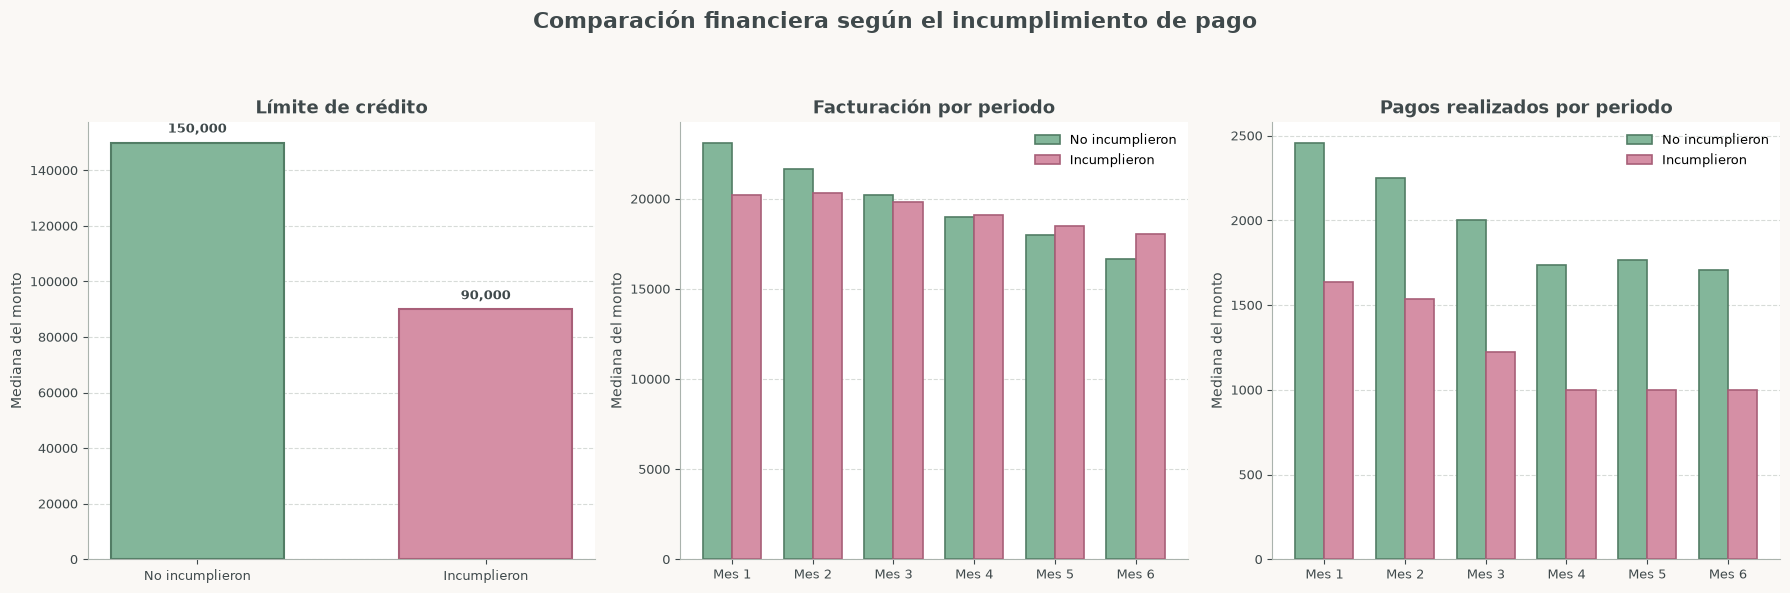

In [66]:
# Comparación de medianas según el incumplimiento
grupo = df.groupby("default payment next month")
medianas = grupo[variables_financieras].median()

# Variables financieras
facturacion = [f"BILL_AMT{i}" for i in range(1, 7)]
pagos = [f"PAY_AMT{i}" for i in range(1, 7)]

# Paleta pastel con mayor intensidad
fondo = "#FAF8F5"
texto = "#3F494B"
color_no = "#83B69A"  # Verde salvia más intenso
color_si = "#D58FA5"  # Rosa empolvado más intenso
borde_no = "#527D65"
borde_si = "#A85F78"

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor(fondo)

# 1. Límite de crédito
ax = axes[0]

valores = [
    medianas.loc[0, "LIMIT_BAL"],
    medianas.loc[1, "LIMIT_BAL"]
]

barras = ax.bar(
    ["No incumplieron", "Incumplieron"],
    valores,
    color=[color_no, color_si],
    edgecolor=[borde_no, borde_si],
    linewidth=1.5,
    width=0.6
)

ax.bar_label(
    barras,
    labels=[f"{v:,.0f}" for v in valores],
    padding=5,
    fontsize=9,
    fontweight="bold",
    color=texto
)

ax.set_title("Límite de crédito", fontweight="bold", fontsize=13)
ax.set_ylabel("Mediana del monto")

# 2. Facturación por periodo
ax = axes[1]
x = np.arange(6)
ancho = 0.36

ax.bar(
    x - ancho / 2,
    medianas.loc[0, facturacion],
    ancho,
    label="No incumplieron",
    color=color_no,
    edgecolor=borde_no,
    linewidth=1.2
)

ax.bar(
    x + ancho / 2,
    medianas.loc[1, facturacion],
    ancho,
    label="Incumplieron",
    color=color_si,
    edgecolor=borde_si,
    linewidth=1.2
)

ax.set_title("Facturación por periodo", fontweight="bold", fontsize=13)
ax.set_ylabel("Mediana del monto")
ax.set_xticks(x, [f"Mes {i}" for i in range(1, 7)])
ax.legend(frameon=False, fontsize=9)

# 3. Pagos realizados por periodo
ax = axes[2]

ax.bar(
    x - ancho / 2,
    medianas.loc[0, pagos],
    ancho,
    label="No incumplieron",
    color=color_no,
    edgecolor=borde_no,
    linewidth=1.2
)

ax.bar(
    x + ancho / 2,
    medianas.loc[1, pagos],
    ancho,
    label="Incumplieron",
    color=color_si,
    edgecolor=borde_si,
    linewidth=1.2
)

ax.set_title("Pagos realizados por periodo", fontweight="bold", fontsize=13)
ax.set_ylabel("Mediana del monto")
ax.set_xticks(x, [f"Mes {i}" for i in range(1, 7)])
ax.legend(frameon=False, fontsize=9)

# Acabado general
for ax in axes:
    ax.set_facecolor("#FFFFFF")
    ax.grid(axis="y", linestyle="--", color="#D3D8D4", alpha=0.9)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#AAB3AD")
    ax.spines["bottom"].set_color("#AAB3AD")

    ax.tick_params(axis="both", colors=texto, labelsize=9)
    ax.title.set_color(texto)
    ax.xaxis.label.set_color(texto)
    ax.yaxis.label.set_color(texto)

fig.suptitle(
    "Comparación financiera según el incumplimiento de pago",
    fontsize=16,
    fontweight="bold",
    color=texto
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()
